In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("..")

import ast
import json
from pathlib import Path
import numpy as np
import dask
import xarray as xr
import rioxarray as rxr
import pandas as pd
import regionmask

import xclim
from xclim import sdba

import rasterio
from rasterio.warp import transform

from dask.diagnostics import ProgressBar

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid", {"grid.color": ".93"})

from src.load_data import ClimateModelData, ClimateReanalysisData
from src.timesteps_adjustments import extract_adjusted_timesteps, get_new_timesteps
from src.utils_xarray import (
    xr_reorder_coords,
    get_time_resolution,
    get_specific_hourly_data,
    get_valid_hours,
    match_time_steps,
    add_noise_to_constant_grid_cells
)
from src.bias_correction_xclim import empirical_quantile_mapping, DICT_DEFAULT_XCLIM_PARAMETERS

In [3]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_figs = Path(paths["path_figs"])

# Load data

In [8]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45, "lat_max": 48, "lon_min": 5.8, "lon_max": 10.8}
extent_european_alps = {"lat_min": 44.4, "lat_max": 48.6, "lon_min": 4.5, "lon_max": 16.5}

## tas

In [9]:
ds_tas_bc_ch = ClimateModelData(path_data_processed /
                                 "cordex_processed" /
                                 "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" /
                                 "bias_corrected" /
                                 "3hr" /
                                 "tas.zarr",
                                 extent=extent_ch)

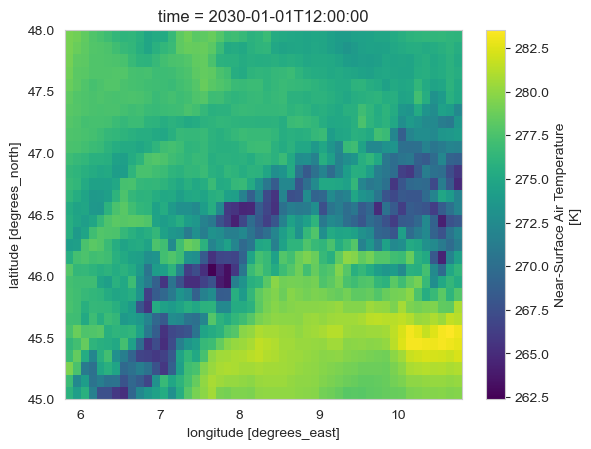

In [10]:
ds_tas_bc_ch.ds_data.sel(time="2030-01-01T12:00:00.000000000").tas.plot()